In [ ]:
import os
import pandas as pd
import urllib.request

RED_PATH = "/content/winequality-red.csv"
WHITE_PATH = "/content/winequality-white.csv"

# Ensure /content directory exists
os.makedirs("/content", exist_ok=True)

# Download the datasets if they do not exist
if not os.path.exists(RED_PATH):
    print("Downloading red wine dataset...")
    urllib.request.urlretrieve("https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv", RED_PATH)

if not os.path.exists(WHITE_PATH):
    print("Downloading white wine dataset...")
    urllib.request.urlretrieve("https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv", WHITE_PATH)

# Verify files are present
assert os.path.exists(RED_PATH), f"Red wine file not found: {RED_PATH}"
assert os.path.exists(WHITE_PATH), f"White wine file not found: {WHITE_PATH}"

# Read clean CSV files (semicolon-separated) for modeling
red_df = pd.read_csv(RED_PATH, sep=";")
white_df = pd.read_csv(WHITE_PATH, sep=";")

print("✅ Red wine dataset successfully verified and loaded:", red_df.shape)
print("✅ White wine dataset successfully verified and loaded:", white_df.shape)


✅ Red wine dataset successfully verified and loaded: (1599, 12)
✅ White wine dataset successfully verified and loaded: (4898, 12)


In [ ]:
!pip install catboost
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
                             classification_report, confusion_matrix, roc_curve, auc)
from imblearn.combine import SMOTETomek
from imblearn.over_sampling import SMOTE
from catboost import CatBoostRegressor
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Set global plotting style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")


In [ ]:
# ============================================================
# 0. Model Definitions
# ============================================================
from sklearn.ensemble import RandomForestClassifier


In [ ]:
# ============================================================
# 1. Training Procedure with Grid Search Optimization
# ============================================================
import os
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV

def train_one_svm_model(X_train, y_train, X_test, y_test, seed=42):
    # Print available CPU cores
    total_cores = os.cpu_count() or 1
    print(f"[System Info] Total CPU cores detected: {total_cores}. Running with n_jobs=-1 (using all cores).")

    """
    Trains a Support Vector Machine (SVM) model with Hyperparameter Grid Search.
    Uses native class weighting to handle class imbalance.
    """
    # Base SVM configuration
    base_model = SVC(
        probability=True,  # Required for predicting probabilities & ROC-AUC
        class_weight='balanced',  # Primary way to handle class imbalance natively
        random_state=seed
    )

    # Hyperparameter grid for SVM
    param_grid = {
        'C': [0.1, 1, 10],
        'gamma': ['scale', 'auto'],
        'kernel': ['rbf', 'linear']
    }

    search = GridSearchCV(
        estimator=base_model,
        param_grid=param_grid,
        cv=10,
        scoring='accuracy',
        n_jobs=-1
    )

    print(f"\n⏳ Running GridSearch CV=10 on SVM for Seed {seed}...")
    search.fit(X_train, y_train)

    print(f"[✅ Seed {seed} Trained] Best Parameters: {search.best_params_} | Best CV Score: {search.best_score_:.4f}")
    return search.best_estimator_

In [ ]:
# ============================================================
# 2. Decision Boundary / Threshold Optimisation
# ============================================================
def threshold_optimize(probs, labels, n_classes):
    if n_classes == 2:
        best_f1, best_t, best_preds = 0, None, None
        for t in np.arange(0.2, 0.8, 0.02):
            preds = (probs[:, 1] > t).astype(int)
            f1 = f1_score(labels, preds, average='macro')
            if f1 > best_f1:
                best_f1, best_t, best_preds = f1, t, preds
        return best_preds
    else:
        best_f1, best_preds = 0, None
        for t_low in np.arange(0.2, 0.8, 0.05):
            for t_high in np.arange(0.2, 0.8, 0.05):
                preds = np.where(probs[:, 0] > t_low, 0, np.where(probs[:, 2] > t_high, 2, 1))
                f1 = f1_score(labels, preds, average='macro')
                if f1 > best_f1:
                    best_f1, best_preds = f1, preds
        return best_preds


In [ ]:
# ============================================================
# 3. High-Quality Data Visualisation Helpers
# ============================================================
def plot_balance_distribution(y_orig, y_res=None, name=""):
    # Safely bypass if resampled data is not provided (e.g., in SVM pipeline)
    if y_res is None:
        # Clean, single-plot mode to show original dataset class distribution
        plt.figure(figsize=(7, 5))
        ax = sns.countplot(x=y_orig, palette="Blues_d")
        plt.title(f"{name} - Dataset Class Distribution", fontsize=14, fontweight="bold")
        plt.xlabel("Class Label")
        plt.ylabel("Count")
        for p in ax.patches:
            ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2., p.get_height()),
                         ha="center", va="bottom", fontsize=12)
        plt.tight_layout()
        plt.show()
        return

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sns.countplot(x=y_orig, ax=axes[0], palette="Blues_d")
    axes[0].set_title(f"{name} - Original Distribution", fontsize=14, fontweight="bold")
    axes[0].set_xlabel("Class Label")
    axes[0].set_ylabel("Count")
    for p in axes[0].patches:
        axes[0].annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2., p.get_height()),
                         ha="center", va="bottom", fontsize=12)

    sns.countplot(x=y_res, ax=axes[1], palette="Oranges_d")
    # axes[1].set_title(f"{name} - After SMOTE-Tomek (2:1)", fontsize=14, fontweight="bold")
    axes[1].set_title(f"{name} - After SMOTE", fontsize=14, fontweight="bold")
    axes[1].set_xlabel("Class Label")
    axes[1].set_ylabel("Count")
    for p in axes[1].patches:
        axes[1].annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2., p.get_height()),
                         ha="center", va="bottom", fontsize=12)
    plt.tight_layout()
    plt.show()

def plot_confusion_matrix(labels, preds, n_classes, name):
    cm = confusion_matrix(labels, preds)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="YlGnBu", cbar=False,
                xticklabels=[f"Class {i}" for i in range(n_classes)],
                yticklabels=[f"Class {i}" for i in range(n_classes)])
    plt.title(f"{name} - Confusion Matrix (Optimized)", fontsize=14, fontweight="bold")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.show()

def plot_roc_curves(labels, probs, n_classes, name):
    plt.figure(figsize=(7, 6))
    if n_classes == 2:
        fpr, tpr, _ = roc_curve(labels, probs[:, 1])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC curve (AUC = {roc_auc:.4f})")
    else:
        from sklearn.preprocessing import label_binarize
        y_bin = label_binarize(labels, classes=range(n_classes))
        colors = ["aqua", "darkorange", "cornflowerblue"]
        for i in range(n_classes):
            fpr, tpr, _ = roc_curve(y_bin[:, i], probs[:, i])
            roc_auc = auc(fpr, tpr)
            plt.plot(fpr, tpr, color=colors[i], lw=2, label=f"Class {i} (AUC = {roc_auc:.4f})")

    plt.plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"{name} - ROC Curves", fontsize=14, fontweight="bold")
    plt.legend(loc="lower right")
    plt.show()

def plot_loss_curves(all_losses, name):
    # Safely bypass if loss list is empty or None
    if all_losses is None or len(all_losses) == 0:
        return
    plt.figure(figsize=(8, 4))
    for i, loss in enumerate(all_losses):
        plt.plot(loss, label=f"Seed {i+1}", alpha=0.7)
    plt.title(f"{name} - Training Loss Across Multiple Seeds", fontsize=14, fontweight="bold")
    plt.xlabel("Epoch")
    plt.ylabel("Focal Loss")
    plt.legend()
    plt.show()

In [ ]:
# ============================================================
# 4. Core Execution Pipeline
# ============================================================
import time

def run_variety_svm(df, name, n_classes, seeds=(42, 123, 2024)):
    print("\n" + "=" * 60)
    print(f"  {name} Wine —— SVM with Class Weighting (No SMOTE)")
    print("=" * 60)

    df = df.copy()

    # Define feature and target variables
    feature_cols = [c for c in df.columns if c not in ["quality", "label"]]
    X = df[feature_cols].values.astype(np.float32)
    y_raw = df["quality"].values.astype(np.int64)

    # 1. Generate Raw Quality Score Distribution Plot (3-9)
    plt.figure(figsize=(8, 5))
    ax = sns.countplot(x=y_raw, palette="viridis")
    plt.title(f"{name} - Raw Quality Distribution (3-9)", fontsize=14, fontweight="bold")
    plt.xlabel("Raw Wine Quality Score")
    plt.ylabel("Count")
    for p in ax.patches:
        ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha="center", va="bottom", fontsize=10, fontweight="bold")
    plt.tight_layout()
    plt.show()

    # Map target scores to classification buckets first (to prevent data leakage)
    if n_classes == 2:
        y = (y_raw >= 7).astype(np.int64)
    else:
        y = np.array([0 if q <= 4 else (1 if q <= 6 else 2) for q in y_raw], dtype=np.int64)

    # 2. Generate class balance distribution plot before training splits
    plot_balance_distribution(y, name=name)

    # Split into Train and Test Sets first
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=42
    )

    # Scale features based only on training set to prevent leakage
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # Track the start of the entire training loop for this variety
    print(f"\n⏱️ Initiating SVM training for {name} across seeds...")
    svm_start_time = time.time()

    # Train and evaluate SVM models across seeds
    best_acc = -1
    best_probs = None
    best_seed = None

    for i, seed in enumerate(seeds):
        print(f"\n--- Training SVM {i+1}/{len(seeds)} (Seed: {seed}) ---")
        model = train_one_svm_model(X_train_scaled, y_train, X_test_scaled, y_test, seed=seed)
        probs = model.predict_proba(X_test_scaled)
        preds = probs.argmax(axis=1)
        acc = accuracy_score(y_test, preds)
        print(f"[Evaluation] SVM with Seed {seed} achieved Test Accuracy: {acc:.4f}")

        if acc > best_acc:
            best_acc = acc
            best_probs = probs
            best_seed = seed

    # Track and print the elapsed training time for this variety
    svm_end_time = time.time()
    elapsed_total = svm_end_time - svm_start_time
    elapsed_min = int(elapsed_total // 60)
    elapsed_sec = int(elapsed_total % 60)
    print(f"\n⏱️ [Completed] SVM training for {name} took: {elapsed_min}m {elapsed_sec}s")

    print(f"\n✨ Selected the best single SVM model with Seed: {best_seed} (Accuracy: {best_acc:.4f})")

    # Optimise prediction thresholds
    preds_opt = threshold_optimize(best_probs, y_test, n_classes)

    acc_final = accuracy_score(y_test, preds_opt)
    f1_final = f1_score(y_test, preds_opt, average="macro")
    try:
        if n_classes > 2:
            auc_score = roc_auc_score(y_test, best_probs, multi_class="ovr", average="macro")
        else:
            auc_score = roc_auc_score(y_test, best_probs[:, 1])
    except:
        auc_score = float("nan")

    print(f"\n[Final SVM Performance] Acc={acc_final:.4f} | F1={f1_final:.4f} | AUC={auc_score:.4f}")

    # Visualisations
    plot_confusion_matrix(y_test, preds_opt, n_classes, f"{name} (SVM)")
    plot_roc_curves(y_test, best_probs, n_classes, f"{name} (SVM)")

    return {"name": name, "n_classes": n_classes, "n_test": len(y_test),
            "acc": acc_final, "f1": f1_final, "auc": auc_score}


✅ GPU detected successfully: NVIDIA L4

  Red Wine Wine —— SVM with Class Weighting (No SMOTE)


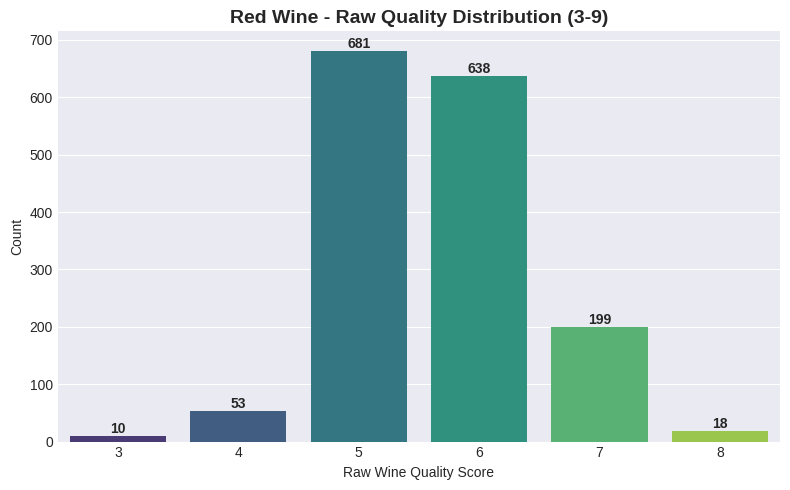

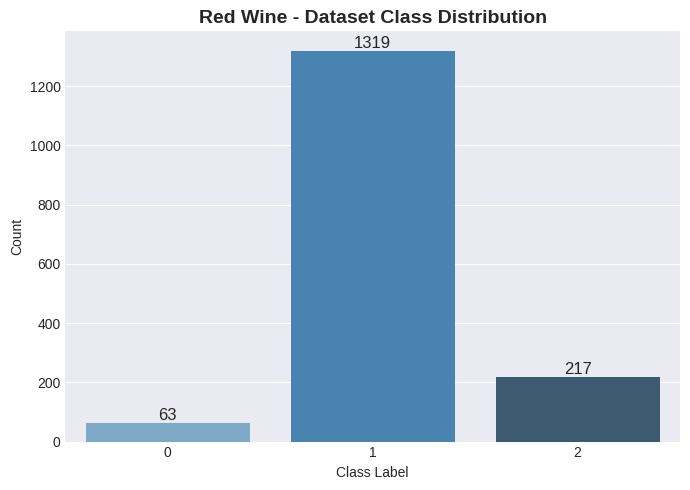


⏱️ Initiating SVM training for Red Wine across seeds...

--- Training SVM 1/3 (Seed: 42) ---
[System Info] Total CPU cores detected: 12. Running with n_jobs=-1 (using all cores).

⏳ Running GridSearch CV=10 on SVM for Seed 42...
[✅ Seed 42 Trained] Best Parameters: {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'} | Best CV Score: 0.7569
[Evaluation] SVM with Seed 42 achieved Test Accuracy: 0.8500

--- Training SVM 2/3 (Seed: 123) ---
[System Info] Total CPU cores detected: 12. Running with n_jobs=-1 (using all cores).

⏳ Running GridSearch CV=10 on SVM for Seed 123...
[✅ Seed 123 Trained] Best Parameters: {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'} | Best CV Score: 0.7569
[Evaluation] SVM with Seed 123 achieved Test Accuracy: 0.8469

--- Training SVM 3/3 (Seed: 2024) ---
[System Info] Total CPU cores detected: 12. Running with n_jobs=-1 (using all cores).

⏳ Running GridSearch CV=10 on SVM for Seed 2024...
[✅ Seed 2024 Trained] Best Parameters: {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'

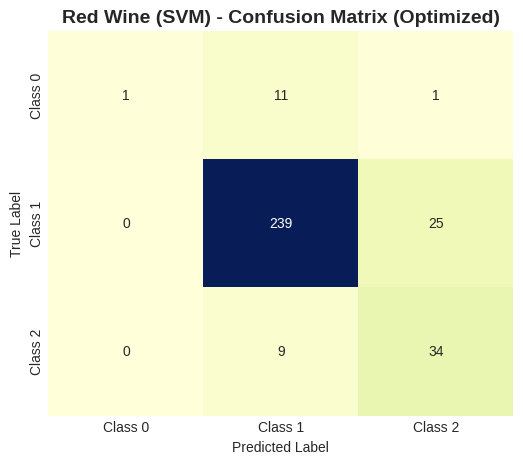

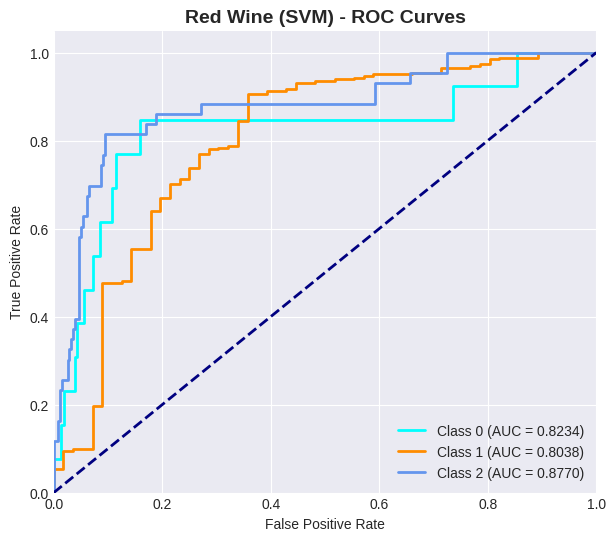


  White Wine Wine —— SVM with Class Weighting (No SMOTE)


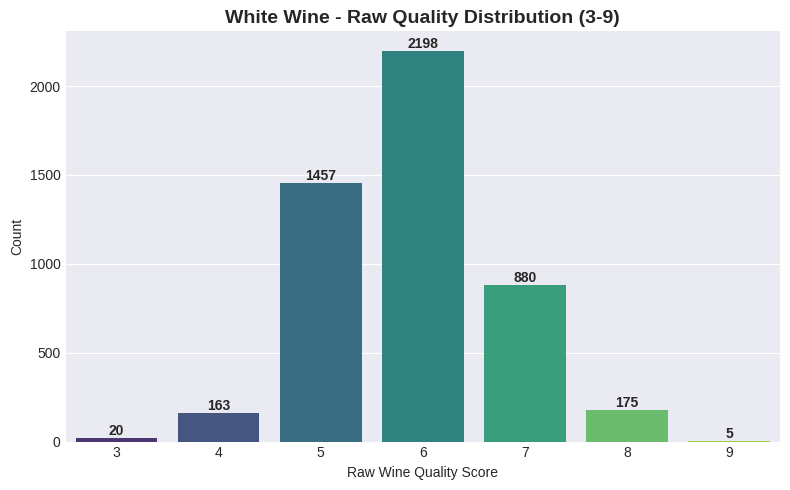

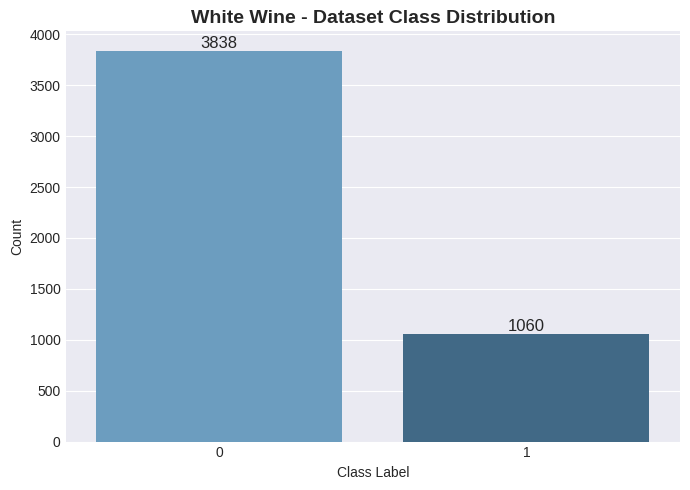


⏱️ Initiating SVM training for White Wine across seeds...

--- Training SVM 1/3 (Seed: 42) ---
[System Info] Total CPU cores detected: 12. Running with n_jobs=-1 (using all cores).

⏳ Running GridSearch CV=10 on SVM for Seed 42...
[✅ Seed 42 Trained] Best Parameters: {'C': 10, 'gamma': 'auto', 'kernel': 'rbf'} | Best CV Score: 0.7654
[Evaluation] SVM with Seed 42 achieved Test Accuracy: 0.8388

--- Training SVM 2/3 (Seed: 123) ---
[System Info] Total CPU cores detected: 12. Running with n_jobs=-1 (using all cores).

⏳ Running GridSearch CV=10 on SVM for Seed 123...
[✅ Seed 123 Trained] Best Parameters: {'C': 10, 'gamma': 'auto', 'kernel': 'rbf'} | Best CV Score: 0.7654
[Evaluation] SVM with Seed 123 achieved Test Accuracy: 0.8398

--- Training SVM 3/3 (Seed: 2024) ---
[System Info] Total CPU cores detected: 12. Running with n_jobs=-1 (using all cores).

⏳ Running GridSearch CV=10 on SVM for Seed 2024...
[✅ Seed 2024 Trained] Best Parameters: {'C': 10, 'gamma': 'auto', 'kernel': 'rbf'}

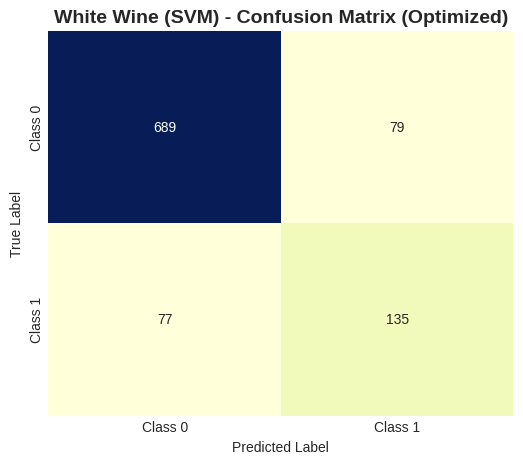

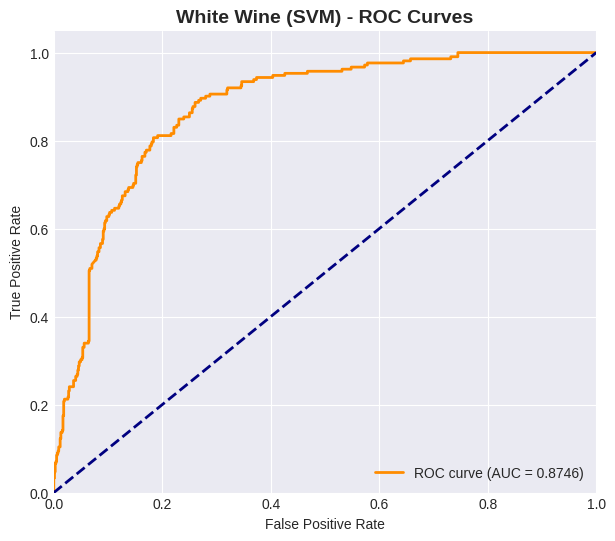


  Generating overall model performance summary plot...


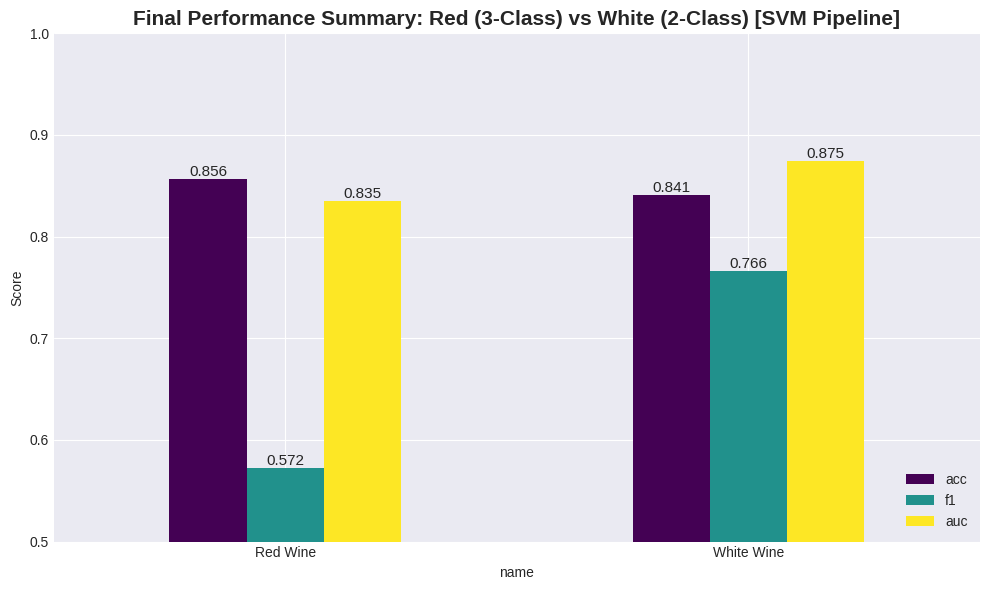

                 acc        f1       auc
name                                    
Red Wine    0.856250  0.572336  0.834733
White Wine  0.840816  0.766054  0.874582


In [ ]:
# ============================================================
# 5. Main Execution
# ============================================================
if __name__ == "__main__":
    red_df = pd.read_csv("/content/winequality-red.csv", sep=";")
    white_df = pd.read_csv("/content/winequality-white.csv", sep=";")

    if torch.cuda.is_available():
        device = torch.device("cuda")
        print(f"\n✅ GPU detected successfully: {torch.cuda.get_device_name(0)}")
    else:
        device = torch.device("cpu")
        print("\n❌ GPU not detected. Training with CPU.")

    # Execute SVM training for both datasets
    svm_red = run_variety_svm(red_df, "Red Wine", n_classes=3, seeds=(42, 123, 2024))
    svm_white = run_variety_svm(white_df, "White Wine", n_classes=2, seeds=(42, 123, 2024))

    # Generate and plot performance comparison bar chart
    print("\n" + "=" * 60)
    print("  Generating overall model performance summary plot...")

    summary_df = pd.DataFrame([svm_red, svm_white]).set_index("name")[["acc", "f1", "auc"]]

    ax = summary_df.plot(kind="bar", figsize=(10, 6), colormap="viridis", rot=0)

    plt.title("Final Performance Summary: Red (3-Class) vs White (2-Class) [SVM Pipeline]", fontsize=15, fontweight="bold")

    plt.ylabel("Score")
    plt.ylim(0.5, 1.0)
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha="center", va="bottom", fontsize=11)
    plt.legend(loc="lower right")
    plt.tight_layout()
    plt.show()

    print(summary_df)